# **GSLC Deep Learning**

> **Oxford-IIIT Pet**

> Michael Ahlovely Stevenson

## **A. Setup Environtment**

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import models, datasets, transforms

In [2]:
def set_seed(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"[INFO] Random Seed Set: {seed}")

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Active Device: {device}")

if device.type == "cuda":
    print(f"[INFO] GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"[INFO] Alocation Memory Left: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("[WARNING] GPU not detected, using CPU instead.")

[INFO] Random Seed Set: 42
[INFO] Active Device: cuda
[INFO] GPU Model: Tesla T4
[INFO] Alocation Memory Left: 15.64 GB


## **B. Pipeline & Preprocessing**

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.models import ResNet18_Weights
from sklearn.model_selection import train_test_split

# Class Target
SELECTED_CLASSES = [
    # 5 Cat Breeds
    "Abyssinian", "Bengal", "Birman", "Bombay", "British_Shorthair",
    # 5 Dog Breeds
    "beagle", "boxer", "chihuahua", "pug", "saint_bernard"
]

print(f"[INFO] Target Classes ({len(SELECTED_CLASSES)} breeds selected): {SELECTED_CLASSES}")

# Pretrained Weights & Pipelines
weights = ResNet18_Weights.IMAGENET1K_V1
imagenet_mean = weights.transforms().mean
imagenet_std = weights.transforms().std

# Pipeline Evaluasi
eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

# Pipeline Data Augmentasi (Buat Train Set Eksperimen B4)
train_augmentation_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

print("[INFO] Data transformation pipelines initialized successfully.")

# Dataset Oxford-IIIT Pet
print("[INFO] Downloading Oxford-IIIT Pet dataset...")
raw_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True,
    transform=None
)

# Class Matching
def normalize_name(name: str) -> str:
    return name.lower().replace(" ", "_").replace("-", "_")

all_dataset_classes = raw_dataset.classes
matched_classes = {}

for target_cls in SELECTED_CLASSES:
    target_norm = normalize_name(target_cls)
    for orig_idx, actual_cls in enumerate(all_dataset_classes):
        if normalize_name(actual_cls) == target_norm:
            matched_classes[target_cls] = (orig_idx, actual_cls)
            break

print(f"[INFO] Successfully matched {len(matched_classes)}/10 target classes in dataset:")
for target_cls, (orig_idx, actual_name) in matched_classes.items():
    print(f"  - Target: '{target_cls}' -> Dataset Name: '{actual_name}' (Original Index: {orig_idx})")

if len(matched_classes) < 10:
    print(f"[WARNING] Expected 10 classes, but found {len(matched_classes)} matching classes.")

# Index Mapping (0..36) -> (0..9)
orig_to_new_label = {
    matched_classes[target_cls][0]: new_idx
    for new_idx, target_cls in enumerate(SELECTED_CLASSES)
}

# Index Filtering
filtered_samples = []
for idx in range(len(raw_dataset)):
    _, orig_label = raw_dataset[idx]
    if orig_label in orig_to_new_label:
        new_label = orig_to_new_label[orig_label]
        filtered_samples.append((idx, new_label))

print(f"[INFO] Total filtered samples across 10 classes: {len(filtered_samples)}")

# Dataset Split (70% Train, 15% Val, 15% Test)
sample_indices = [item[0] for item in filtered_samples]
sample_labels = [item[1] for item in filtered_samples]

train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    sample_indices,
    sample_labels,
    test_size=0.30,
    stratify=sample_labels,
    random_state=SEED
)

val_idx, test_idx, val_labels, test_labels = train_test_split(
    temp_idx,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

print(f"[INFO] Dataset Split Completed -> Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}")

# Custom Dataset Wrapper
class OxfordPetSubsetDataset(Dataset):
    def __init__(self, base_ds, indices, labels, transform=None):
        self.base_ds = base_ds
        self.indices = indices
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        raw_idx = self.indices[idx]
        image, _ = self.base_ds[raw_idx]

        if self.transform is not None:
            image = self.transform(image)

        label = self.labels[idx]
        return image, label

# Init Dataset PyTorch
train_dataset = OxfordPetSubsetDataset(raw_dataset, train_idx, train_labels, transform=eval_transforms)
train_dataset_augmented = OxfordPetSubsetDataset(raw_dataset, train_idx, train_labels, transform=train_augmentation_transforms)
val_dataset = OxfordPetSubsetDataset(raw_dataset, val_idx, val_labels, transform=eval_transforms)
test_dataset = OxfordPetSubsetDataset(raw_dataset, test_idx, test_labels, transform=eval_transforms)

# DataLoaders (Batch Size = 32)
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
train_loader_aug = DataLoader(train_dataset_augmented, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"[INFO] DataLoaders created successfully with Batch Size: {BATCH_SIZE}")
print(f"[INFO] Number of Batches -> Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

[INFO] Target Classes (10 breeds selected): ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'beagle', 'boxer', 'chihuahua', 'pug', 'saint_bernard']
[INFO] Data transformation pipelines initialized successfully.
[INFO] Downloading Oxford-IIIT Pet dataset...


100%|██████████| 792M/792M [00:21<00:00, 36.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.4MB/s]


[INFO] Successfully matched 10/10 target classes in dataset:
  - Target: 'Abyssinian' -> Dataset Name: 'Abyssinian' (Original Index: 0)
  - Target: 'Bengal' -> Dataset Name: 'Bengal' (Original Index: 5)
  - Target: 'Birman' -> Dataset Name: 'Birman' (Original Index: 6)
  - Target: 'Bombay' -> Dataset Name: 'Bombay' (Original Index: 7)
  - Target: 'British_Shorthair' -> Dataset Name: 'British Shorthair' (Original Index: 9)
  - Target: 'beagle' -> Dataset Name: 'Beagle' (Original Index: 4)
  - Target: 'boxer' -> Dataset Name: 'Boxer' (Original Index: 8)
  - Target: 'chihuahua' -> Dataset Name: 'Chihuahua' (Original Index: 10)
  - Target: 'pug' -> Dataset Name: 'Pug' (Original Index: 25)
  - Target: 'saint_bernard' -> Dataset Name: 'Saint Bernard' (Original Index: 28)
[INFO] Total filtered samples across 10 classes: 996
[INFO] Dataset Split Completed -> Train: 697 | Validation: 149 | Test: 150
[INFO] DataLoaders created successfully with Batch Size: 32
[INFO] Number of Batches -> Train: 2

## **C. Framework Modelling, Evaluation, and Logging**

In [4]:
import time
import copy
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

# Parameter Model Counter
def count_parameters(model: nn.Module):
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"[INFO] Trainable Parameters: {trainable_params:,} / Total Parameters: {total_params:,} "
          f"({(trainable_params / total_params) * 100:.2f}% active)")
    return trainable_params, total_params


# Early Stopping
class EarlyStopping:
    def __init__(self, patience: int = 4, delta: float = 1e-4, verbose: bool = True):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.best_model_weights = None

    def __call__(self, val_loss: float, model: nn.Module):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f"[WARNING] EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss: float, model: nn.Module):
        if self.verbose:
            print(f" Validation loss decreased ({self.val_loss_min:.4f} --> {val_loss:.4f}). Saving best weights...")
        self.val_loss_min = val_loss
        self.best_model_weights = copy.deepcopy(model.state_dict())


# Training & Validation Loop
def train_model(model: nn.Module,
                train_loader,
                val_loader,
                criterion,
                optimizer,
                scheduler=None,
                num_epochs: int = 25,
                patience: int = 4,
                device=device):

    early_stopping = EarlyStopping(patience=patience, verbose=True)
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'epoch_times': []
    }

    total_start_time = time.time()

    for epoch in range(1, num_epochs + 1):
        epoch_start_time = time.time()

        # -- Training --
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels.data).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train

        # --- Validation --
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_val += torch.sum(preds == labels.data).item()
                total_val += labels.size(0)

        epoch_val_loss = running_val_loss / total_val
        epoch_val_acc = correct_val / total_val

        if scheduler is not None:
            scheduler.step()

        epoch_duration = time.time() - epoch_start_time

        # History
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        history['epoch_times'].append(epoch_duration)

        print(f" Epoch {epoch:02d}/{num_epochs:02d} | "
              f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc*100:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc*100:.2f}% | "
              f"Time: {epoch_duration:.2f}s")

        early_stopping(epoch_val_loss, model)
        if early_stopping.early_stop:
            print(f"[WARNING] Early stopping triggered at epoch {epoch}.")
            break

    total_training_time = time.time() - total_start_time
    print(f"[INFO] Total Training Duration: {total_training_time:.2f} seconds ({total_training_time/60:.2f} minutes)")

    if early_stopping.best_model_weights is not None:
        model.load_state_dict(early_stopping.best_model_weights)
        print("[INFO] Restored best model weights based on minimum validation loss.")

    return history, total_training_time, len(history['train_loss'])


def evaluate_on_test_set(model: nn.Module, test_loader, criterion, device=device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    test_loss = running_loss / len(test_loader.dataset)
    test_acc = accuracy_score(all_targets, all_preds)
    test_macro_f1 = f1_score(all_targets, all_preds, average='macro')

    print(f"[INFO] Test Set Results -> Loss: {test_loss:.4f} | Accuracy: {test_acc*100:.2f}% | Macro F1-Score: {test_macro_f1:.4f}")
    return test_loss, test_acc, test_macro_f1, np.array(all_preds), np.array(all_targets)

print("[INFO] Training and evaluation framework initialized successfully.")

[INFO] Training and evaluation framework initialized successfully.


## **D. Experiment**

- **B1**: Baseline from Scratch (Pelatihan ResNet-18 dari inisialisasi acak)
- **B2**: Feature Extraction (ResNet-18 pretrained dengan pembekuan seluruh backbone)
- **B3**: Progressive Fine-Tuning (Unfreeze `layer4` dan `fc` dengan *differential learning rate*)
- **B4**: Uji Kontrol Data Augmentation (Eksperimen dengan pipeline augmentasi aktif)
- **B5**: Arsitektur Pembanding / Bonus (Evaluasi efisiensi pada MobileNetV3-Small / EfficientNet-B0)

In [5]:
results_summary = {}

criterion = nn.CrossEntropyLoss()
NUM_EPOCHS = 25
PATIENCE = 4

### **Eksperimen B1: Baseline from Scratch**
Pelatihan ResNet-18 dari inisialisasi bobot acak (`weights=None`) tanpa menggunakan representasi *pretrained*

In [6]:
print("\n" + "="*60)
print("[INFO] STARTING EXPERIMENT B1: Baseline from Scratch")
print("="*60)

set_seed(SEED)

# ResNet-18 Tanpa Pretrained Weights
model_b1 = models.resnet18(weights=None)
num_ftrs = model_b1.fc.in_features
model_b1.fc = nn.Linear(num_ftrs, 10)
model_b1 = model_b1.to(device)

trainable_b1, total_b1 = count_parameters(model_b1)

optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

history_b1, time_b1, epoch_conv_b1 = train_model(
    model=model_b1,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b1,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=device
)

test_loss_b1, test_acc_b1, test_f1_b1, preds_b1, targets_b1 = evaluate_on_test_set(
    model=model_b1,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

results_summary['B1_Scratch'] = {
    'Strategy': 'From Scratch',
    'Trainable_Params': trainable_b1,
    'Learning_Rate': '1e-3',
    'Epochs_Converged': epoch_conv_b1,
    'Training_Time_Sec': round(time_b1, 2),
    'Best_Val_Acc': round(max(history_b1['val_acc']), 4),
    'Test_Acc': round(test_acc_b1, 4),
    'Test_Macro_F1': round(test_f1_b1, 4),
    'History': history_b1
}


[INFO] STARTING EXPERIMENT B1: Baseline from Scratch
[INFO] Random Seed Set: 42
[INFO] Trainable Parameters: 11,181,642 / Total Parameters: 11,181,642 (100.00% active)
 Epoch 01/25 | Train Loss: 2.3301 - Train Acc: 22.38% | Val Loss: 8.6480 - Val Acc: 17.45% | Time: 8.00s
 Validation loss decreased (inf --> 8.6480). Saving best weights...
 Epoch 02/25 | Train Loss: 1.8872 - Train Acc: 35.58% | Val Loss: 2.4337 - Val Acc: 16.11% | Time: 4.66s
 Validation loss decreased (8.6480 --> 2.4337). Saving best weights...
 Epoch 03/25 | Train Loss: 1.8446 - Train Acc: 35.58% | Val Loss: 2.3836 - Val Acc: 22.15% | Time: 7.74s
 Validation loss decreased (2.4337 --> 2.3836). Saving best weights...
 Epoch 04/25 | Train Loss: 1.7348 - Train Acc: 37.88% | Val Loss: 2.2309 - Val Acc: 27.52% | Time: 4.73s
 Validation loss decreased (2.3836 --> 2.2309). Saving best weights...
 Epoch 05/25 | Train Loss: 1.6043 - Train Acc: 46.20% | Val Loss: 2.4292 - Val Acc: 23.49% | Time: 5.85s
[WARNING] EarlyStopping c

### **Eksperimen B2: Feature Extraction**
Menggunakan ResNet-18 *pretrained* dengan membekukan seluruh lapisan *backbone* (`requires_grad = False`) dan hanya melatih *classifier head* (`model.fc`)

In [7]:
print("\n" + "="*60)
print("[INFO] STARTING EXPERIMENT B2: Feature Extraction")
print("="*60)

set_seed(SEED)

model_b2 = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# Freeze Backbone
for param in model_b2.parameters():
    param.requires_grad = False

# Ganti Head
num_ftrs = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_ftrs, 10)
model_b2 = model_b2.to(device)

trainable_b2, total_b2 = count_parameters(model_b2)

optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

history_b2, time_b2, epoch_conv_b2 = train_model(
    model=model_b2,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b2,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=device
)

test_loss_b2, test_acc_b2, test_f1_b2, preds_b2, targets_b2 = evaluate_on_test_set(
    model=model_b2,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

results_summary['B2_Feature_Extraction'] = {
    'Strategy': 'Feature Extraction',
    'Trainable_Params': trainable_b2,
    'Learning_Rate': '1e-3 (fc only)',
    'Epochs_Converged': epoch_conv_b2,
    'Training_Time_Sec': round(time_b2, 2),
    'Best_Val_Acc': round(max(history_b2['val_acc']), 4),
    'Test_Acc': round(test_acc_b2, 4),
    'Test_Macro_F1': round(test_f1_b2, 4),
    'History': history_b2
}


[INFO] STARTING EXPERIMENT B2: Feature Extraction
[INFO] Random Seed Set: 42
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 118MB/s]


[INFO] Trainable Parameters: 5,130 / Total Parameters: 11,181,642 (0.05% active)
 Epoch 01/25 | Train Loss: 1.7860 - Train Acc: 44.19% | Val Loss: 1.1067 - Val Acc: 80.54% | Time: 5.05s
 Validation loss decreased (inf --> 1.1067). Saving best weights...
 Epoch 02/25 | Train Loss: 0.8137 - Train Acc: 91.25% | Val Loss: 0.5727 - Val Acc: 93.29% | Time: 4.25s
 Validation loss decreased (1.1067 --> 0.5727). Saving best weights...
 Epoch 03/25 | Train Loss: 0.5021 - Train Acc: 94.26% | Val Loss: 0.4043 - Val Acc: 93.29% | Time: 5.01s
 Validation loss decreased (0.5727 --> 0.4043). Saving best weights...
 Epoch 04/25 | Train Loss: 0.3554 - Train Acc: 96.56% | Val Loss: 0.3232 - Val Acc: 94.63% | Time: 5.17s
 Validation loss decreased (0.4043 --> 0.3232). Saving best weights...
 Epoch 05/25 | Train Loss: 0.2823 - Train Acc: 97.27% | Val Loss: 0.2777 - Val Acc: 93.96% | Time: 4.28s
 Validation loss decreased (0.3232 --> 0.2777). Saving best weights...
 Epoch 06/25 | Train Loss: 0.2203 - Train 

### **Eksperimen B3: Progressive Fine-Tuning**
Membuka pembekuan (*unfreeze*) pada blok residual terakhir (`layer4`) serta lapisan `fc` dengan *differential learning rate* (`1e-4` untuk `layer4` dan `1e-3` untuk `fc`)

In [8]:
print("\n" + "="*60)
print("[INFO] STARTING EXPERIMENT B3: Progressive Fine-Tuning")
print("="*60)

set_seed(SEED)

model_b3 = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# Freeze Backbone
for param in model_b3.parameters():
    param.requires_grad = False

# Unfreeze layer4
for param in model_b3.layer4.parameters():
    param.requires_grad = True

# Ganti classifier head
num_ftrs = model_b3.fc.in_features
model_b3.fc = nn.Linear(num_ftrs, 10)
model_b3 = model_b3.to(device)

trainable_b3, total_b3 = count_parameters(model_b3)

# Differential Learning Rate Optimizer
optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

history_b3, time_b3, epoch_conv_b3 = train_model(
    model=model_b3,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b3,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=device
)

test_loss_b3, test_acc_b3, test_f1_b3, preds_b3, targets_b3 = evaluate_on_test_set(
    model=model_b3,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

results_summary['B3_Fine_Tuning'] = {
    'Strategy': 'Progressive Fine-Tuning',
    'Trainable_Params': trainable_b3,
    'Learning_Rate': 'layer4: 1e-4, fc: 1e-3',
    'Epochs_Converged': epoch_conv_b3,
    'Training_Time_Sec': round(time_b3, 2),
    'Best_Val_Acc': round(max(history_b3['val_acc']), 4),
    'Test_Acc': round(test_acc_b3, 4),
    'Test_Macro_F1': round(test_f1_b3, 4),
    'History': history_b3
}


[INFO] STARTING EXPERIMENT B3: Progressive Fine-Tuning
[INFO] Random Seed Set: 42
[INFO] Trainable Parameters: 8,398,858 / Total Parameters: 11,181,642 (75.11% active)
 Epoch 01/25 | Train Loss: 1.0035 - Train Acc: 72.31% | Val Loss: 0.1973 - Val Acc: 95.30% | Time: 4.29s
 Validation loss decreased (inf --> 0.1973). Saving best weights...
 Epoch 02/25 | Train Loss: 0.1029 - Train Acc: 98.71% | Val Loss: 0.1424 - Val Acc: 95.97% | Time: 5.57s
 Validation loss decreased (0.1973 --> 0.1424). Saving best weights...
 Epoch 03/25 | Train Loss: 0.0415 - Train Acc: 99.86% | Val Loss: 0.1277 - Val Acc: 95.97% | Time: 4.32s
 Validation loss decreased (0.1424 --> 0.1277). Saving best weights...
 Epoch 04/25 | Train Loss: 0.0179 - Train Acc: 100.00% | Val Loss: 0.1172 - Val Acc: 96.64% | Time: 4.27s
 Validation loss decreased (0.1277 --> 0.1172). Saving best weights...
 Epoch 05/25 | Train Loss: 0.0114 - Train Acc: 100.00% | Val Loss: 0.1318 - Val Acc: 96.64% | Time: 5.68s
[WARNING] EarlyStopping

### **Eksperimen B4: Uji Kontrol Data Augmentation**
Melatih konfigurasi Progressive Fine-Tuning menggunakan pipeline *Data Augmentation* aktif (`train_loader_aug`) untuk dievaluasi dampaknya terhadap *overfitting* dan generalisasi

In [9]:
print("\n" + "="*60)
print("[INFO] STARTING EXPERIMENT B4: Fine-Tuning with Data Augmentation")
print("="*60)

set_seed(SEED)

model_b4 = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

for param in model_b4.parameters():
    param.requires_grad = False

for param in model_b4.layer4.parameters():
    param.requires_grad = True

num_ftrs = model_b4.fc.in_features
model_b4.fc = nn.Linear(num_ftrs, 10)
model_b4 = model_b4.to(device)

trainable_b4, total_b4 = count_parameters(model_b4)

optimizer_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

history_b4, time_b4, epoch_conv_b4 = train_model(
    model=model_b4,
    train_loader=train_loader_aug,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b4,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=device
)

test_loss_b4, test_acc_b4, test_f1_b4, preds_b4, targets_b4 = evaluate_on_test_set(
    model=model_b4,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

results_summary['B4_Augmented_FT'] = {
    'Strategy': 'Fine-Tuning + Augmentation',
    'Trainable_Params': trainable_b4,
    'Learning_Rate': 'layer4: 1e-4, fc: 1e-3',
    'Epochs_Converged': epoch_conv_b4,
    'Training_Time_Sec': round(time_b4, 2),
    'Best_Val_Acc': round(max(history_b4['val_acc']), 4),
    'Test_Acc': round(test_acc_b4, 4),
    'Test_Macro_F1': round(test_f1_b4, 4),
    'History': history_b4
}


[INFO] STARTING EXPERIMENT B4: Fine-Tuning with Data Augmentation
[INFO] Random Seed Set: 42
[INFO] Trainable Parameters: 8,398,858 / Total Parameters: 11,181,642 (75.11% active)
 Epoch 01/25 | Train Loss: 1.1246 - Train Acc: 69.15% | Val Loss: 0.2135 - Val Acc: 93.29% | Time: 7.36s
 Validation loss decreased (inf --> 0.2135). Saving best weights...
 Epoch 02/25 | Train Loss: 0.2100 - Train Acc: 96.27% | Val Loss: 0.1794 - Val Acc: 94.63% | Time: 7.04s
 Validation loss decreased (0.2135 --> 0.1794). Saving best weights...
 Epoch 03/25 | Train Loss: 0.1065 - Train Acc: 97.99% | Val Loss: 0.1619 - Val Acc: 94.63% | Time: 6.65s
 Validation loss decreased (0.1794 --> 0.1619). Saving best weights...
 Epoch 04/25 | Train Loss: 0.0520 - Train Acc: 99.43% | Val Loss: 0.1807 - Val Acc: 94.63% | Time: 7.23s
[WARNING] EarlyStopping counter: 1 out of 4
 Epoch 05/25 | Train Loss: 0.0378 - Train Acc: 100.00% | Val Loss: 0.1715 - Val Acc: 95.30% | Time: 6.36s
[WARNING] EarlyStopping counter: 2 out o

### **Eksperimen B5: Arsitektur Pembanding**
Evaluasi arsitektur modern berorientasi efisiensi komputasi (`MobileNetV3-Small`) guna membandingkan *trade-off* performa, jumlah parameter, dan durasi komputasi

In [10]:
print("\n" + "="*60)
print("[INFO] STARTING EXPERIMENT B5: Comparative Architecture (MobileNetV3-Small)")
print("="*60)

set_seed(SEED)

# Inisialisasi MobileNetV3-Small Pretrained
mobilenet_weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
model_b5 = models.mobilenet_v3_small(weights=mobilenet_weights)

# Bekukan seluruh backbone
for param in model_b5.parameters():
    param.requires_grad = False

# Ganti classifier head (MobileNetV3 memiliki struktur classifier khusus)
in_features = model_b5.classifier[3].in_features
model_b5.classifier[3] = nn.Linear(in_features, 10)
model_b5 = model_b5.to(device)

trainable_b5, total_b5 = count_parameters(model_b5)

optimizer_b5 = torch.optim.AdamW(model_b5.classifier[3].parameters(), lr=1e-3, weight_decay=1e-2)

history_b5, time_b5, epoch_conv_b5 = train_model(
    model=model_b5,
    train_loader=train_loader_aug,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_b5,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=device
)

test_loss_b5, test_acc_b5, test_f1_b5, preds_b5, targets_b5 = evaluate_on_test_set(
    model=model_b5,
    test_loader=test_loader,
    criterion=criterion,
    device=device
)

results_summary['B5_MobileNetV3_Small'] = {
    'Strategy': 'MobileNetV3 (Feature Ext.)',
    'Trainable_Params': trainable_b5,
    'Learning_Rate': '1e-3',
    'Epochs_Converged': epoch_conv_b5,
    'Training_Time_Sec': round(time_b5, 2),
    'Best_Val_Acc': round(max(history_b5['val_acc']), 4),
    'Test_Acc': round(test_acc_b5, 4),
    'Test_Macro_F1': round(test_f1_b5, 4),
    'History': history_b5
}

print("\n[INFO] All experiment conditions (B1 - B5) completed successfully.")


[INFO] STARTING EXPERIMENT B5: Comparative Architecture (MobileNetV3-Small)
[INFO] Random Seed Set: 42
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 80.5MB/s]

[INFO] Trainable Parameters: 10,250 / Total Parameters: 1,528,106 (0.67% active)


 Epoch 01/25 | Train Loss: 1.7847 - Train Acc: 49.93% | Val Loss: 0.8812 - Val Acc: 85.91% | Time: 7.71s
 Validation loss decreased (inf --> 0.8812). Saving best weights...
 Epoch 02/25 | Train Loss: 0.9828 - Train Acc: 86.23% | Val Loss: 0.4791 - Val Acc: 91.95% | Time: 5.95s
 Validation loss decreased (0.8812 --> 0.4791). Saving best weights...
 Epoch 03/25 | Train Loss: 0.6656 - Train Acc: 91.25% | Val Loss: 0.3423 - Val Acc: 93.29% | Time: 7.34s
 Validation loss decreased (0.4791 --> 0.3423). Saving best weights...
 Epoch 04/25 | Train Loss: 0.5211 - Train Acc: 92.83% | Val Loss: 0.2873 - Val Acc: 94.63% | Time: 5.79s
 Validation loss decreased (0.3423 --> 0.2873). Saving best weights...
 Epoch 05/25 | Train Loss: 0.4376 - Train Acc: 92.25% | Val Loss: 0.2664 - Val Acc: 93.96% | Time: 7.22s
 Validation loss decreased (0.2873 --> 0.2664). Saving best weights...
 Epoch 06/25 | Train Loss: 0.3744 - Train Acc: 93.69% | Val Loss: 0.2551 - Val Acc: 91.95% | Time: 5.82s
 Validation loss d

# **E. Visualisation & Summary**

[INFO] Summary Matrix of All Experimental Conditions:


,Strategy,Trainable_Params,Learning_Rate,Epochs_Converged,Training_Time_Sec,Best_Val_Acc,Test_Acc,Test_Macro_F1
B1_Scratch,From Scratch,11181642,1e-3,17,92.13,0.4295,0.4800,0.4699
B2_Feature_Extraction,Feature Extraction,5130,1e-3 (fc only),25,125.34,0.9530,0.9333,0.9327
B3_Fine_Tuning,Progressive Fine-Tuning,8398858,"layer4: 1e-4, fc: 1e-3",12,57.91,0.9732,0.9467,0.9467
B4_Augmented_FT,Fine-Tuning + Augmentation,8398858,"layer4: 1e-4, fc: 1e-3",7,48.27,0.9530,0.9467,0.9461
B5_MobileNetV3_Small,MobileNetV3 (Feature Ext.),10250,1e-3,14,91.48,0.9463,0.9067,0.9063


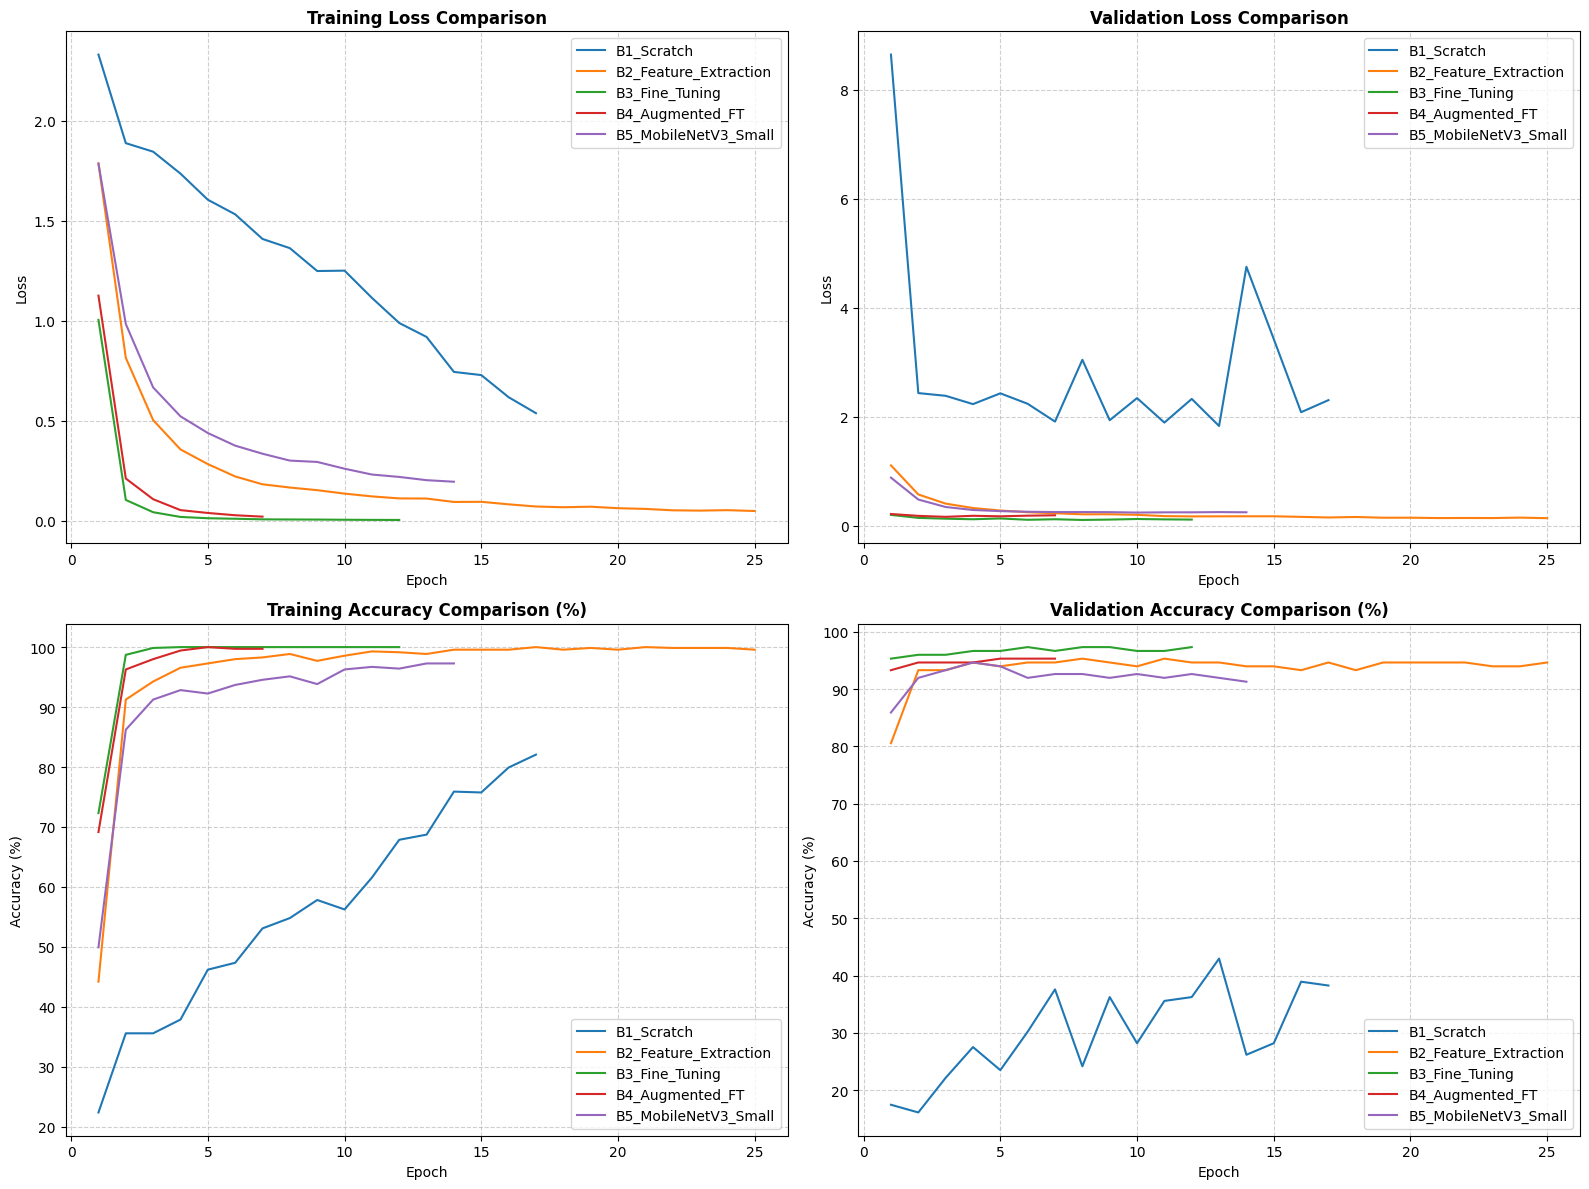

[INFO] Comparative learning curves plotted successfully.


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df_summary = pd.DataFrame.from_dict(results_summary, orient='index')
df_display = df_summary.drop(columns=['History'])

print("[INFO] Summary Matrix of All Experimental Conditions:")
display(df_display)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Training Loss
for exp_name, data in results_summary.items():
    epochs = range(1, len(data['History']['train_loss']) + 1)
    axes[0, 0].plot(epochs, data['History']['train_loss'], label=f"{exp_name}")
axes[0, 0].set_title('Training Loss Comparison', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Validation Loss
for exp_name, data in results_summary.items():
    epochs = range(1, len(data['History']['val_loss']) + 1)
    axes[0, 1].plot(epochs, data['History']['val_loss'], label=f"{exp_name}")
axes[0, 1].set_title('Validation Loss Comparison', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Plot 3: Training Accuracy
for exp_name, data in results_summary.items():
    epochs = range(1, len(data['History']['train_acc']) + 1)
    axes[1, 0].plot(epochs, [acc * 100 for acc in data['History']['train_acc']], label=f"{exp_name}")
axes[1, 0].set_title('Training Accuracy Comparison (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# Plot 4: Validation Accuracy
for exp_name, data in results_summary.items():
    epochs = range(1, len(data['History']['val_acc']) + 1)
    axes[1, 1].plot(epochs, [acc * 100 for acc in data['History']['val_acc']], label=f"{exp_name}")
axes[1, 1].set_title('Validation Accuracy Comparison (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("[INFO] Comparative learning curves plotted successfully.")

# **F. Failure Analysis**


[INFO] Visualizing misclassified samples for Best Model (B4):


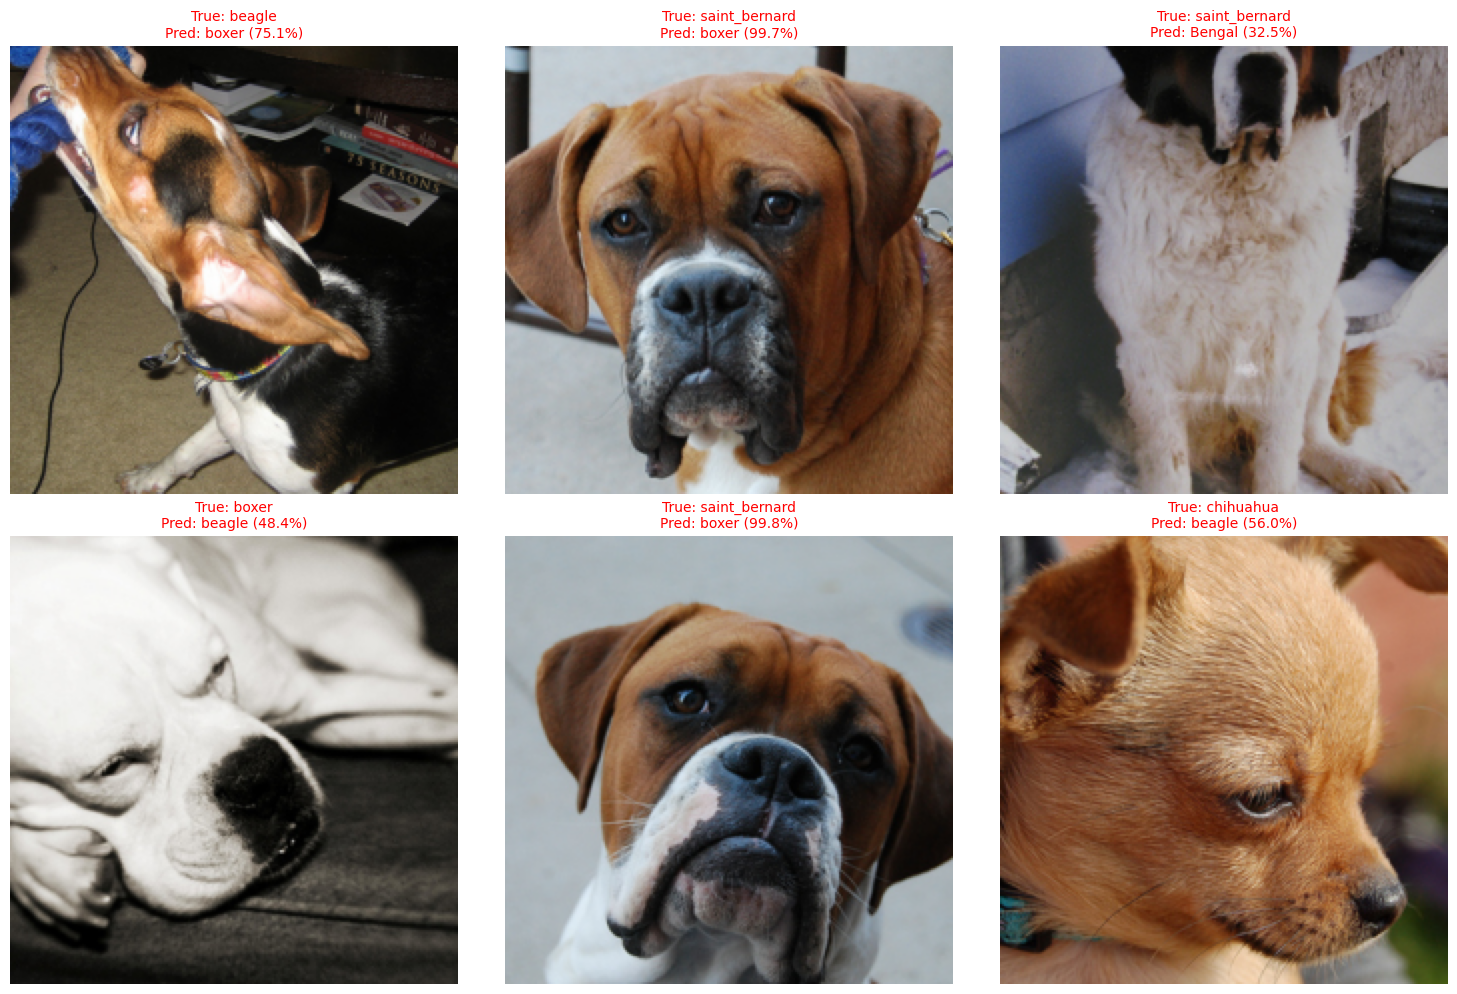

In [12]:
import torch.nn.functional as F

def unnormalize(tensor, mean=imagenet_mean, std=imagenet_std):
    """
    Mengembalikan tensor gambar yang dinormalisasi ke rentang nilai piksel asli [0, 1].
    """
    tensor = tensor.clone()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

def visualize_misclassifications(model, test_loader, class_names, num_samples=6, device=device):
    model.eval()
    misclassified_images = []
    misclassified_preds = []
    misclassified_targets = []
    misclassified_probs = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probabilities = F.softmax(outputs, dim=1)
            confidences, preds = torch.max(probabilities, 1)

            incorrect_mask = (preds != labels)

            for img, pred, target, prob in zip(images[incorrect_mask], preds[incorrect_mask], labels[incorrect_mask], confidences[incorrect_mask]):
                misclassified_images.append(img.cpu())
                misclassified_preds.append(pred.item())
                misclassified_targets.append(target.item())
                misclassified_probs.append(prob.item())

                if len(misclassified_images) >= num_samples:
                    break

            if len(misclassified_images) >= num_samples:
                break

    if len(misclassified_images) == 0:
        print("[INFO] No misclassified samples found on the test set!")
        return

    # Visualisasi Grid
    rows = (len(misclassified_images) + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for idx in range(len(misclassified_images)):
        img_unnorm = unnormalize(misclassified_images[idx]).permute(1, 2, 0).numpy()
        pred_label = class_names[misclassified_preds[idx]]
        true_label = class_names[misclassified_targets[idx]]
        confidence = misclassified_probs[idx] * 100

        axes[idx].imshow(img_unnorm)
        axes[idx].set_title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color='red', fontsize=10)
        axes[idx].axis('off')

    # Sembunyikan subplot kosong
    for idx in range(len(misclassified_images), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

print("[INFO] Visualizing misclassified samples for Best Model (B4):")
visualize_misclassifications(model_b4, test_loader, SELECTED_CLASSES, num_samples=6)

# **G. Visualisasi Fitur (Grad-CAM)**

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


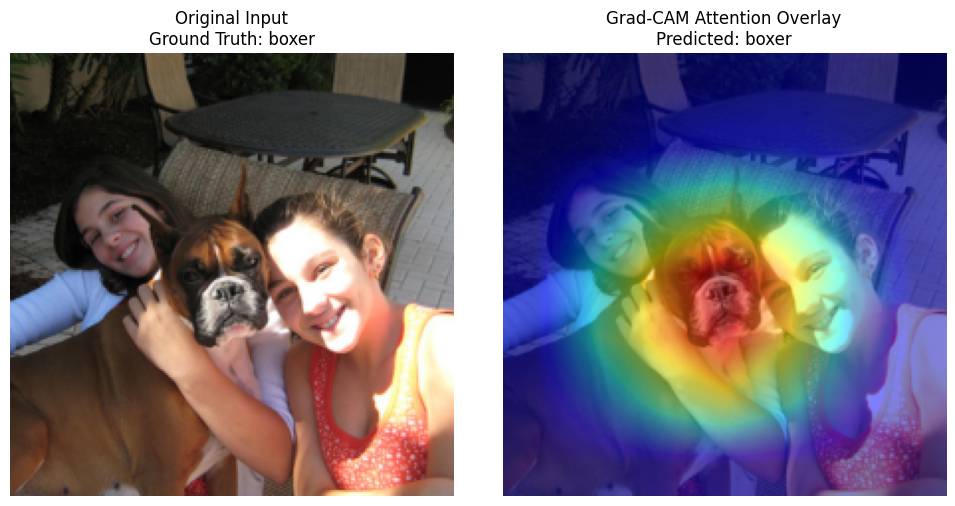

[INFO] Grad-CAM activation visualization completed successfully.


In [13]:
import cv2

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, target_class=None):
        self.model.eval()
        output = self.model(input_image)

        if target_class is None:
            target_class = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        score = output[0, target_class]
        score.backward()

        gradients = self.gradients[0].cpu().data.numpy()
        activations = self.activations[0].cpu().data.numpy()

        weights = np.mean(gradients, axis=(1, 2))
        cam = np.zeros(activations.shape[1:], dtype=np.float32)

        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]

        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224, 224))
        cam = cam - np.min(cam)
        if np.max(cam) != 0:
            cam = cam / np.max(cam)
        return cam, target_class


grad_cam = GradCAM(model_b4, model_b4.layer4)

sample_img, sample_label = test_dataset[0]
input_tensor = sample_img.unsqueeze(0).to(device)

heatmap, pred_class = grad_cam.generate_heatmap(input_tensor, target_class=sample_label)

# Un-normalize Gambar Asli
img_original = unnormalize(sample_img).permute(1, 2, 0).numpy()

# Format Visualisasi Heatmap
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_original)
plt.title(f"Original Input\nGround Truth: {SELECTED_CLASSES[sample_label]}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_original)
plt.imshow(heatmap, cmap='jet', alpha=0.5)
plt.title(f"Grad-CAM Attention Overlay\nPredicted: {SELECTED_CLASSES[pred_class]}")
plt.axis('off')

plt.tight_layout()
plt.show()

print("[INFO] Grad-CAM activation visualization completed successfully.")

# **H. Export Log**

In [14]:
import json

json_export_data = {}

for exp_name, data in results_summary.items():
    json_export_data[exp_name] = {
        'Strategy': data['Strategy'],
        'Trainable_Params': data['Trainable_Params'],
        'Learning_Rate': data['Learning_Rate'],
        'Epochs_Converged': data['Epochs_Converged'],
        'Training_Time_Sec': data['Training_Time_Sec'],
        'Best_Val_Acc': data['Best_Val_Acc'],
        'Test_Acc': data['Test_Acc'],
        'Test_Macro_F1': data['Test_Macro_F1'],
        'History': {
            'train_loss': [float(v) for v in data['History']['train_loss']],
            'train_acc': [float(v) for v in data['History']['train_acc']],
            'val_loss': [float(v) for v in data['History']['val_loss']],
            'val_acc': [float(v) for v in data['History']['val_acc']],
            'epoch_times': [float(v) for v in data['History']['epoch_times']]
        }
    }

# Format JSON
json_filepath = "experiment_metrics.json"
with open(json_filepath, 'w') as f:
    json.dump(json_export_data, f, indent=4)

print(f"[INFO] Raw metric log saved to JSON: {json_filepath}")

# Format CSV
csv_filepath = "experiment_metrics.csv"
df_display.to_csv(csv_filepath, index_label="Condition_Code")

print(f"[INFO] Summary metric log saved to CSV: {csv_filepath}")

[INFO] Raw metric log saved to JSON: experiment_metrics.json
[INFO] Summary metric log saved to CSV: experiment_metrics.csv


In [15]:
# Note: Hanya untuk di Colab, Uncomment jika ingin digunakan
# from google.colab import files

# files.download('experiment_metrics.json')
# files.download('experiment_metrics.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>